# 02 — Paradoxo do aniversário no futebol

O paradoxo clássico supõe aniversários independentes e uniformes em 365 dias. Aqui comparamos essa referência com 3.026 partidas do Brasileirão Série A (2018–2025) e com a distribuição de nascimento dos jogadores.

**Pergunta:** em uma partida, a chance de dois titulares compartilharem dia e mês de nascimento é a mesma prevista pelo modelo clássico?

## 1. Desenho da análise

A unidade principal é a partida com **22 titulares**. O grupo de **23 jogadores** (22 titulares + 1 reserva sorteado no notebook 01) aparece apenas como comparação direta com o número famoso do paradoxo.

Ignoramos 29/02 no modelo de 365 dias. As partidas repetem jogadores; portanto, os intervalos de Wilson são descritivos e não demonstram causalidade.

In [1]:
from math import factorial, prod, sqrt
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from scipy import stats
from IPython.display import display

pd.set_option("display.max_columns", 60)

PROJECT_DIR = Path.cwd().resolve()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data" / "brasileirao_serie_a_2018_2025"
ANALYSIS_DIR = PROJECT_DIR / "data" / "analysis"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

BLUE = "#06478f"
RED = "#b01f16"
INK = "#111111"
GRAY = "#6b7280"
LIGHT_GRAY = "#d1d5db"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "black",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "font.size": 11,
    "savefig.facecolor": "white",
})


def style_axis(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("black")
    ax.spines[["left", "bottom"]].set_linewidth(1)
    ax.grid(False)
    for label in [*ax.get_xticklabels(), *ax.get_yticklabels()]:
        label.set_fontweight("bold")

In [2]:
paths = {
    "coverage": DATA_DIR / "brasileirao_serie_a_2018_2025_extraction_coverage.csv",
    "selected": DATA_DIR / "brasileirao_serie_a_2018_2025_selected_23_players.csv",
    "unique": DATA_DIR / "brasileirao_serie_a_2018_2025_unique_players.csv",
}
missing = [path for path in paths.values() if not path.exists()]
if missing:
    raise FileNotFoundError(f"Arquivos ausentes: {missing}. Execute o notebook 01.")

coverage_df = pd.read_csv(paths["coverage"], dtype={"game_id": "string"})
coverage_df["date"] = pd.to_datetime(coverage_df["date"], errors="coerce").dt.date

selected_players_df = pd.read_csv(
    paths["selected"], dtype={"game_id": "string", "player_id": "string"}
)
selected_players_df["birth_date"] = pd.to_datetime(
    selected_players_df["birth_date"], errors="coerce"
)

complete_ids = set(coverage_df.loc[coverage_df["status"].eq("complete"), "game_id"])
analysis_players_df = selected_players_df.loc[
    selected_players_df["game_id"].isin(complete_ids)
].copy()
analysis_players_df["birth_day_month"] = analysis_players_df["birth_date"].dt.strftime("%m-%d")

quality = analysis_players_df.groupby("game_id").agg(
    selected=("player_id", "size"),
    known_birthdays=("birth_date", "count"),
    starters=("role", lambda values: values.eq("titular").sum()),
    sampled_reserves=("role", lambda values: values.eq("reserva_sorteado").sum()),
)
assert quality.eq(
    {"selected": 23, "known_birthdays": 23, "starters": 22, "sampled_reserves": 1}
).all().all()

print(f"Partidas completas: {len(complete_ids):,} de {len(coverage_df):,}".replace(",", "."))
print(f"Jogadores por partida: 22 titulares + 1 reserva sorteado")

Partidas completas: 3.026 de 3.040
Jogadores por partida: 22 titulares + 1 reserva sorteado


## 2. A referência combinatória

Com \(n\) pessoas há \(\binom{n}{2}=n(n-1)/2\) pares: **231** pares entre 22 titulares e **253** entre 23 jogadores.

Sob uniformidade e independência, calculamos primeiro o complemento — todos os aniversários diferentes:

\[
P_{\mathrm{unif}}(\text{coincidência}\mid n)
=1-\prod_{k=0}^{n-1}\frac{365-k}{365}.
\]

Isso produz 47,6% para \(n=22\) e 50,7% para \(n=23\).

In [3]:
def uniform_collision_probability(n, days=365):
    return 1 - prod((days - k) / days for k in range(n))


def wilson_interval(successes, observations, z=1.96):
    proportion = successes / observations
    denominator = 1 + z**2 / observations
    center = (proportion + z**2 / (2 * observations)) / denominator
    margin = z * sqrt(
        proportion * (1 - proportion) / observations
        + z**2 / (4 * observations**2)
    ) / denominator
    return center - margin, center + margin


def collision_flags(frame, expected_size):
    group_sizes = frame.groupby("game_id").size()
    unique_birthdays = frame.groupby("game_id")["birth_day_month"].nunique()
    assert group_sizes.eq(expected_size).all()
    return unique_birthdays.lt(expected_size)


starters_df = analysis_players_df.loc[analysis_players_df["role"].eq("titular")].copy()
flags_22 = collision_flags(starters_df, 22)
flags_23 = collision_flags(analysis_players_df, 23)

match_results_df = coverage_df.loc[
    coverage_df["game_id"].isin(complete_ids),
    ["game_id", "season", "round", "date", "home_team", "away_team"],
].copy()
match_results_df = match_results_df.join(
    flags_22.rename("shared_birthday_22_starters"), on="game_id"
).join(
    flags_23.rename("shared_birthday_23_with_sampled_reserve"), on="game_id"
)


def summarize(frame, column, group_size, group_definition):
    observations = len(frame)
    successes = int(frame[column].sum())
    observed = successes / observations
    low, high = wilson_interval(successes, observations)
    theoretical = uniform_collision_probability(group_size)
    return {
        "group_definition": group_definition,
        "group_size": group_size,
        "matches": observations,
        "matches_with_shared_birthday": successes,
        "observed_probability": observed,
        "confidence_95_low": low,
        "confidence_95_high": high,
        "uniform_probability": theoretical,
        "difference_percentage_points": 100 * (observed - theoretical),
    }


definitions = [
    ("shared_birthday_22_starters", 22, "22 titulares"),
    ("shared_birthday_23_with_sampled_reserve", 23, "22 titulares + 1 reserva sorteado"),
]
overall_summary_df = pd.DataFrame(
    [summarize(match_results_df, column, n, label) for column, n, label in definitions]
)

season_records = []
for season, frame in match_results_df.groupby("season", sort=True):
    for column, n, label in definitions:
        season_records.append({"season": season, **summarize(frame, column, n, label)})
season_summary_df = pd.DataFrame(season_records)

display(
    overall_summary_df[
        [
            "group_definition", "matches", "matches_with_shared_birthday",
            "observed_probability", "uniform_probability",
            "difference_percentage_points",
        ]
    ].style.format({
        "observed_probability": "{:.1%}",
        "uniform_probability": "{:.1%}",
        "difference_percentage_points": "{:+.1f} p.p.",
    })
)

,group_definition,matches,matches_with_shared_birthday,observed_probability,uniform_probability,difference_percentage_points
0,22 titulares,3026,1622,53.6%,47.6%,+6.0 p.p.
1,22 titulares + 1 reserva sorteado,3026,1717,56.7%,50.7%,+6.0 p.p.


## 3. Quando os dias não são equiprováveis

Se \(p_d\) é a proporção de jogadores nascidos no dia \(d\), a probabilidade de não haver repetição é o polinômio simétrico elementar:

\[
P_{\mathbf p}(\text{todos diferentes}\mid n)
=n!\sum_{i_1<\cdots<i_n}p_{i_1}\cdots p_{i_n}.
\]

Logo, \(P_{\mathbf p}(\text{coincidência})=1-P_{\mathbf p}(\text{todos diferentes})\). Calculamos essa soma por programação dinâmica — sem ruído de Monte Carlo. A distribuição uniforme minimiza a chance de coincidência entre distribuições independentes.

In [4]:
players_df = pd.read_csv(paths["unique"], dtype={"player_id": "string"})
players_df["birth_date"] = pd.to_datetime(players_df["birth_date"], errors="coerce")
players_df = players_df.dropna(subset=["birth_date"])
players_df = players_df.loc[
    ~(
        players_df["birth_date"].dt.month.eq(2)
        & players_df["birth_date"].dt.day.eq(29)
    )
].copy()
players_df["birth_day_month"] = players_df["birth_date"].dt.strftime("%m-%d")
players_df["birth_month"] = players_df["birth_date"].dt.month

calendar = pd.date_range("2001-01-01", "2001-12-31")
calendar_days = calendar.strftime("%m-%d")
day_counts = (
    players_df["birth_day_month"]
    .value_counts()
    .reindex(calendar_days, fill_value=0)
)
day_probabilities = day_counts.to_numpy() / day_counts.sum()

month_counts = players_df["birth_month"].value_counts().reindex(range(1, 13), fill_value=0)
month_share = month_counts / month_counts.sum()
days_per_month = calendar.to_series().groupby(calendar.month).size().to_numpy()
expected_month_share = days_per_month / 365

chi2_day, p_day = stats.chisquare(
    day_counts.to_numpy(),
    np.full(365, day_counts.sum() / 365),
)
chi2_month, p_month = stats.chisquare(
    month_counts.to_numpy(),
    month_counts.sum() * expected_month_share,
)


def empirical_collision_curve(probabilities, max_n):
    coefficients = np.zeros(max_n + 1)
    coefficients[0] = 1.0
    for probability in probabilities:
        for degree in range(max_n, 0, -1):
            coefficients[degree] += probability * coefficients[degree - 1]

    no_collision = np.array([
        factorial(n) * coefficients[n] for n in range(1, max_n + 1)
    ])
    return np.clip(1 - no_collision, 0, 1)


MAX_GROUP_SIZE = 60
group_sizes = np.arange(1, MAX_GROUP_SIZE + 1)
uniform_curve = np.array([
    uniform_collision_probability(n) for n in group_sizes
])
empirical_curve = empirical_collision_curve(day_probabilities, MAX_GROUP_SIZE)

curve_df = pd.DataFrame({
    "group_size": group_sizes,
    "uniform_probability": uniform_curve,
    "empirical_player_distribution_probability": empirical_curve,
})

overall_summary_df["empirical_player_distribution_probability"] = (
    overall_summary_df["group_size"].map(
        curve_df.set_index("group_size")[
            "empirical_player_distribution_probability"
        ]
    )
)

test_summary_df = pd.DataFrame({
    "escala": ["365 dias", "12 meses"],
    "qui_quadrado": [chi2_day, chi2_month],
    "graus_de_liberdade": [364, 11],
    "p_valor": [p_day, p_month],
})
print(f"Jogadores únicos (sem 29/02): {len(players_df):,}".replace(",", "."))
display(test_summary_df.style.format({"qui_quadrado": "{:.1f}", "p_valor": "{:.2e}"}))

Jogadores únicos (sem 29/02): 2.931


,escala,qui_quadrado,graus_de_liberdade,p_valor
0,365 dias,707.7,364,2.59e-24
1,12 meses,329.9,11,4.25e-64


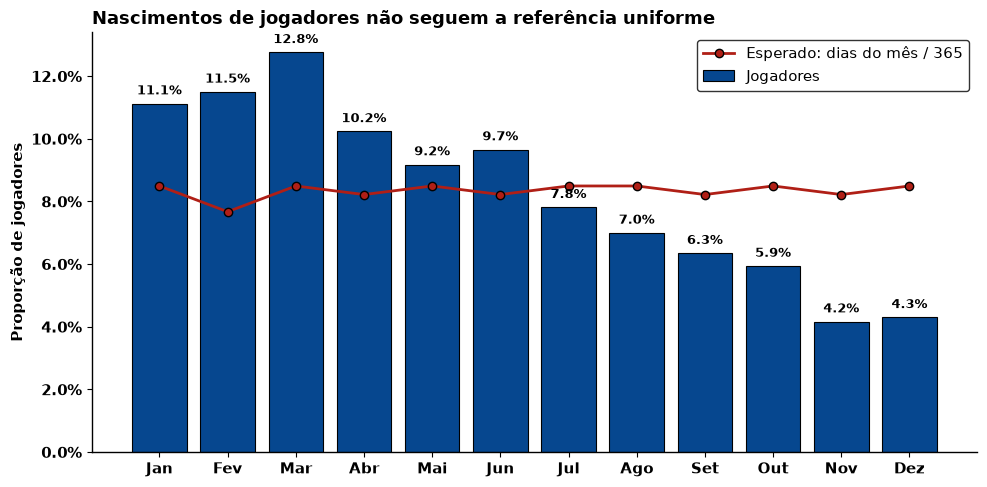

In [5]:
month_labels = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
                "Jul", "Ago", "Set", "Out", "Nov", "Dez"]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(
    month_labels,
    month_share.to_numpy(),
    color=BLUE,
    edgecolor="black",
    linewidth=0.8,
    label="Jogadores",
)
ax.plot(
    month_labels,
    expected_month_share,
    color=RED,
    marker="o",
    markeredgecolor="black",
    linewidth=2,
    label="Esperado: dias do mês / 365",
)
ax.set_title("Nascimentos de jogadores não seguem a referência uniforme", loc="left")
ax.set_ylabel("Proporção de jogadores")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(frameon=True, edgecolor="black")
style_axis(ax)

for bar, value in zip(bars, month_share):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.002,
        f"{value:.1%}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
    )

fig.tight_layout()
fig.savefig(
    ANALYSIS_DIR / "brasileirao_serie_a_2018_2025_birth_month_distribution.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

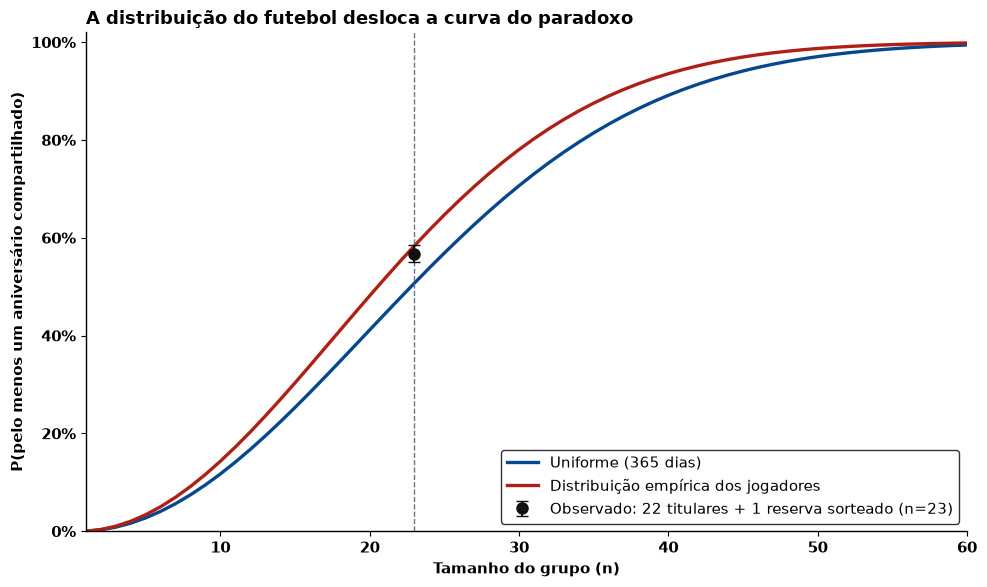

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(
    group_sizes,
    uniform_curve,
    color=BLUE,
    linewidth=2.4,
    label="Uniforme (365 dias)",
)
ax.plot(
    group_sizes,
    empirical_curve,
    color=RED,
    linewidth=2.4,
    label="Distribuição empírica dos jogadores",
)

row_23 = overall_summary_df.loc[
    overall_summary_df["group_size"].eq(23)
].iloc[0]
ax.errorbar(
    23,
    row_23["observed_probability"],
    yerr=[[
        row_23["observed_probability"] - row_23["confidence_95_low"]
    ], [
        row_23["confidence_95_high"] - row_23["observed_probability"]
    ]],
    fmt="o",
    color=INK,
    markerfacecolor=INK,
    markeredgecolor=INK,
    markersize=8,
    capsize=4,
    linewidth=1.4,
    label="Observado: 22 titulares + 1 reserva sorteado (n=23)",
    zorder=5,
)

ax.axvline(23, color=GRAY, linestyle="--", linewidth=1)
ax.set_title("A distribuição do futebol desloca a curva do paradoxo", loc="left")
ax.set_xlabel("Tamanho do grupo (n)")
ax.set_ylabel("P(pelo menos um aniversário compartilhado)")
ax.set_xlim(1, MAX_GROUP_SIZE)
ax.set_ylim(0, 1.02)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(frameon=True, edgecolor="black", loc="lower right")
style_axis(ax)

fig.tight_layout()
fig.savefig(
    ANALYSIS_DIR / "brasileirao_serie_a_2018_2025_birthday_paradox_curve.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

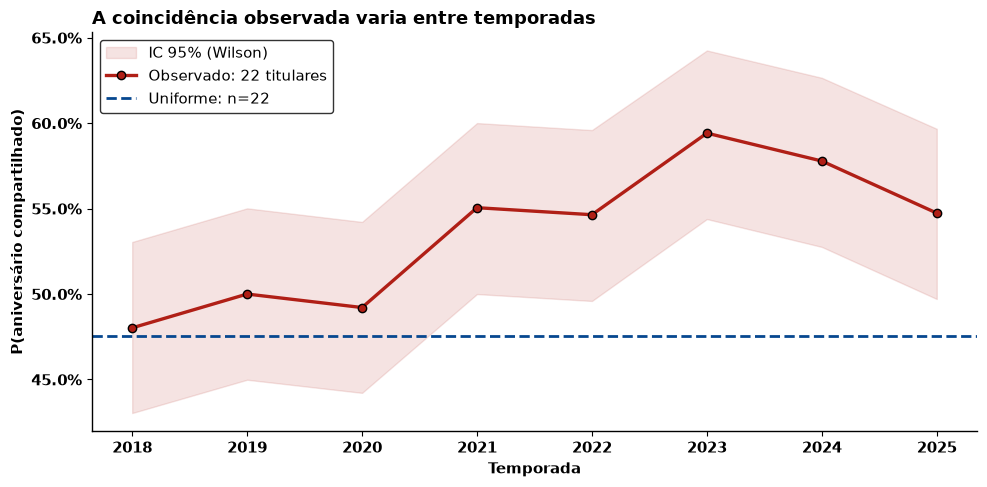

In [7]:
season_22 = season_summary_df.loc[
    season_summary_df["group_size"].eq(22)
].sort_values("season")

fig, ax = plt.subplots(figsize=(10, 5))
ax.fill_between(
    season_22["season"],
    season_22["confidence_95_low"],
    season_22["confidence_95_high"],
    color=RED,
    alpha=0.12,
    label="IC 95% (Wilson)",
)
ax.plot(
    season_22["season"],
    season_22["observed_probability"],
    color=RED,
    marker="o",
    markeredgecolor="black",
    linewidth=2.4,
    label="Observado: 22 titulares",
)
ax.axhline(
    uniform_collision_probability(22),
    color=BLUE,
    linestyle="--",
    linewidth=2,
    label="Uniforme: n=22",
)
ax.set_title("A coincidência observada varia entre temporadas", loc="left")
ax.set_xlabel("Temporada")
ax.set_ylabel("P(aniversário compartilhado)")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(frameon=True, edgecolor="black")
style_axis(ax)

fig.tight_layout()
fig.savefig(
    ANALYSIS_DIR / "brasileirao_serie_a_2018_2025_season_trend.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 4. Leitura dos resultados

- **22 titulares:** 53,6% das partidas têm coincidência, contra 47,6% no modelo uniforme.
- **Ponte com o paradoxo:** em 23 jogadores, são 56,7% observados contra 50,7% no clássico.
- **Distribuição empírica:** o modelo independente baseado nos jogadores eleva a referência para cerca de 55,0% em \(n=22\), aproximando-se do observado.

A concentração de nascimentos no início do ano é compatível com o **efeito da idade relativa**, documentado no futebol. Porém, esta análise não separa esse mecanismo da sazonalidade da população, da seleção de atletas, da composição dos elencos e da repetição de jogadores entre partidas.

In [8]:
shared_counts_22 = starters_df.groupby(
    ["game_id", "birth_day_month"]
)["player_id"].transform("size")
shared_players_df = starters_df.loc[shared_counts_22.ge(2)].copy()

overall_summary_df.to_csv(
    ANALYSIS_DIR / "brasileirao_serie_a_2018_2025_shared_birthday_overall.csv",
    index=False,
)
season_summary_df.to_csv(
    ANALYSIS_DIR / "brasileirao_serie_a_2018_2025_shared_birthday_by_season.csv",
    index=False,
)
match_results_df.to_csv(
    ANALYSIS_DIR / "brasileirao_serie_a_2018_2025_shared_birthday_match_results.csv",
    index=False,
)
shared_players_df.to_csv(
    ANALYSIS_DIR / "brasileirao_serie_a_2018_2025_shared_birthday_players.csv",
    index=False,
)
curve_df.to_csv(
    ANALYSIS_DIR / "brasileirao_serie_a_2018_2025_birthday_paradox_curve.csv",
    index=False,
)
day_counts.rename("players").rename_axis("birth_day_month").reset_index().to_csv(
    ANALYSIS_DIR / "brasileirao_serie_a_2018_2025_birth_day_counts.csv",
    index=False,
)

print(f"Tabelas e figuras salvas em: {ANALYSIS_DIR}")

Tabelas e figuras salvas em: /Users/gabrielcarbinatto/Documents/GitHub/football-birthday-paradox/data/analysis


## 5. Referências

- McGregor, R. J.; Shannon, G. P. (2004). [On the generalised birthday problem](https://doi.org/10.1017/S0025557200174972).
- Berresford, G. C. (1980). [The Uniformity Assumption in the Birthday Problem](https://doi.org/10.1080/0025570X.1980.11976872).
- Fadnavis, S. (2011). [A generalization of the Birthday problem and the chromatic polynomial](https://arxiv.org/abs/1105.0698).
- Rabelo et al. (2016). [Efeito da idade relativa nas categorias do futebol brasileiro](https://doi.org/10.1016/j.rbce.2016.01.001).
- Bozděch, Agricola & Zháněl (2023). [The Relative Age Effect at Different Age Periods in Soccer: A Meta-Analysis](https://doi.org/10.1177/00315125231210585).